# Audited Execution Notebook
## Strict-Inductive Elliptic Bitcoin AML Benchmark

This notebook runs the benchmark from the raw Elliptic CSV files and generates fresh tables, figures, metrics, predictions, and a dataset manifest. **Use the values from this execution when updating the manuscript; the previous paper values are not assumed to match this run.** Record the dataset hashes and environment with any reported results.

### Audit fixes implemented
| Audit item | Notebook implementation |
|---|---|
| Random forest | **80 trees across ten seeds**; reports mean and SD |
| HGB | **200 iterations with early stopping disabled** |
| MLP | **Mini-batch 256**, balanced class weights, early stopping on validation AUPRC |
| Row order | Canonical `(time step, txId)` order for reproducible runs on the same files |
| Predictions | Saves a `.npy` probability array for every model run |
| Run-level files | Writes `all_run_metrics.csv` and per-model CSVs; retains `per_run_metrics.csv` for compatibility |
| Seed-42 spot check | Retrains and compares the full-edge, no-edge, local-93, classical-head, and VQC records |
| Paired statistics | Reports seeds favouring A, bootstrap intervals, exact sign-flip tests, and Holm-adjusted p-values |
| H2 encoder robustness | Keeps the paper's seed-42 shared-encoder analysis as primary and adds a one-encoder-per-seed analysis as secondary |
| Fig. 10 | Shades and annotates test time steps with fewer than 10 illicit cases |
| Manuscript values | Generates `manuscript_values.md` from the current run; do not copy old manuscript numbers over these results |

### Interpretation and data
The primary VQC-versus-classical result is **conditional on the shared encoder trained with seed 42**. The one-encoder-per-seed analysis measures encoder variability but is secondary; interpret it separately unless the manuscript's analysis plan is revised. The exact sign-flip test is the prespecified inferential test; the percentile bootstrap interval is descriptive and can disagree with it at ten pairs.

Place the `elliptic_bitcoin_dataset` folder beside this notebook or under `data/`, or place the original dataset ZIP beside it. The preflight cell also checks common Downloads locations. The final `manuscript_values.md` and `dataset_manifest.json` record the run's metrics and input-file SHA-256 hashes.

## 0. Install requirements
Plain PyTorch is used for both graph propagation and the four-qubit state-vector VQC, so `torch-geometric` and
`pennylane` are not required.

In [1]:
# Uncomment if needed:
# %pip install numpy pandas scipy scikit-learn torch matplotlib

## 1. Complete experiment code
Run once. Writes everything to `./elliptic_final_run/outputs/`. On a 2-core CPU it takes roughly 15-25 minutes
(the ten-seed mini-batch MLP and the encoder-robustness block dominate). Set `RUN_ENCODER_ROBUSTNESS = False` or
`RUN_SPOT_CHECK = False` at the top of the cell to skip those blocks.

In [2]:
from pathlib import Path
import os

required = (
    'elliptic_txs_features.csv',
    'elliptic_txs_classes.csv',
    'elliptic_txs_edgelist.csv',
)

roots = [
    Path('/kaggle/input/datasets/annamdevula/elliptical-bitcoin'),
    Path('/kaggle/input/elliptical-bitcoin'),
]
candidates = []
for root in roots:
    if root.is_dir():
        candidates.append(root)
        candidates.extend(path.parent for path in root.rglob(required[0]))

DATA_SOURCE = next(
    (
        path for path in candidates
        if all((path / filename).is_file() for filename in required)
    ),
    None,
)
if DATA_SOURCE is None:
    raise FileNotFoundError(
        'Could not find the three Elliptic CSV files under '
        '/kaggle/input/datasets/annamdevula/elliptical-bitcoin. '
        'Check the dataset mount and filenames.'
    )

WORK_DIR = Path('/kaggle/working')
os.chdir(WORK_DIR)

dataset_link = WORK_DIR / 'elliptic_bitcoin_dataset'
if not dataset_link.exists():
    dataset_link.symlink_to(DATA_SOURCE, target_is_directory=True)
elif not all((dataset_link / filename).is_file() for filename in required):
    raise FileExistsError(
        f'{dataset_link} exists but does not contain the expected CSV files.'
    )

print('Dataset:', DATA_SOURCE)
print('Writable output directory:', Path.cwd())

Dataset: /kaggle/input/datasets/annamdevula/elliptical-bitcoin
Writable output directory: /kaggle/working


In [3]:
import os, sys, json, random, time, hashlib, platform, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_score, recall_score
import sklearn
import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings('ignore')

# =====================================================================
# Configuration (every value below is the value stated in the manuscript)
# =====================================================================
SEEDS = [7, 19, 31, 42, 73, 101, 123, 314, 777, 2024]
REFERENCE_SEED = 42                       # shared-encoder seed and per-time-step reference seed
RF_CFG  = dict(n_estimators=80, max_depth=16, max_features='sqrt', min_samples_leaf=2,
               class_weight='balanced_subsample')                     # Sec. 4.4: 80 trees, ten seeds
HGB_CFG = dict(max_iter=200, learning_rate=0.08, max_leaf_nodes=31, l2_regularization=1.0,
               class_weight='balanced', early_stopping=False)         # Sec. 4.4: 200 iterations (no hidden early stop)
MLP_CFG = dict(hidden=(64, 32), dropout=0.3, lr=1e-3, weight_decay=1e-4, batch_size=256,
               max_epochs=150, patience=20)                           # Sec. 4.4: batch 256, balanced weights, early stopping
GCN_CFG = dict(hidden=39, dropout=0.5, lr=0.01, weight_decay=5e-4, max_epochs=200, patience=20)   # Sec. 4.5.1
ENC_CFG = dict(hidden=32, dropout=0.5, lr=0.01, weight_decay=5e-4, max_epochs=200, patience=20)   # Sec. 4.6.1
HEAD_CFG = dict(lr=0.01, weight_decay=1e-4, max_epochs=100, patience=15, n_per_class=128)         # Sec. 4.6.2-4.6.3
BOOTSTRAP_B, BOOTSTRAP_SEED = 20000, 20260910
RUN_ENCODER_ROBUSTNESS = True             # secondary analysis: one encoder per paired seed
RUN_SPOT_CHECK = True                     # Sec. 5.1: seed-42 records re-trained from scratch and compared

# ---------- Portable notebook paths ----------
ROOT = Path.cwd() / 'elliptic_final_run'
ROOT.mkdir(parents=True, exist_ok=True)

def resolve_data_dir():
    required = ['elliptic_txs_features.csv', 'elliptic_txs_classes.csv', 'elliptic_txs_edgelist.csv']
    candidates = [
        Path.cwd() / 'elliptic_bitcoin_dataset',
        Path.cwd() / 'data' / 'elliptic_bitcoin_dataset',
        ROOT / 'data' / 'elliptic_bitcoin_dataset',
        Path('/mnt/data/elliptic_bitcoin_dataset'),
        Path('/mnt/data/final_truth_run/data/elliptic_bitcoin_dataset'),
    ]
    for d in candidates:
        if all((d / f).exists() for f in required):
            return d
    zip_candidates = list(Path.cwd().glob('*.zip')) + (list(Path('/mnt/data').glob('*.zip')) if Path('/mnt/data').exists() else [])
    for zp in zip_candidates:
        try:
            import zipfile
            with zipfile.ZipFile(zp) as z:
                names = z.namelist()
                if all(any(n.endswith(r) for n in names) for r in required):
                    target = ROOT / 'data'; target.mkdir(parents=True, exist_ok=True); z.extractall(target)
                    for f in target.rglob(required[0]):
                        if all((f.parent / r).exists() for r in required):
                            return f.parent
        except Exception:
            pass
    raise FileNotFoundError('Could not locate the Elliptic dataset. Put the folder `elliptic_bitcoin_dataset` '
                            'beside this notebook, under `data/`, or place the original dataset ZIP beside the notebook.')

DATA = resolve_data_dir()
OUT = ROOT / 'outputs'; OUT.mkdir(parents=True, exist_ok=True)
CKPT = OUT / 'checkpoints'; CKPT.mkdir(exist_ok=True)
PRED = OUT / 'predictions'; PRED.mkdir(exist_ok=True)
PER_MODEL = OUT / 'per_model_metrics'; PER_MODEL.mkdir(exist_ok=True)
print('Using dataset:', DATA)
print('Outputs will be written to:', OUT)
DEVICE = torch.device('cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))

LOG = []
def log(*args):
    s = ' '.join(str(x) for x in args); print(s, flush=True); LOG.append(s)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    try: torch.use_deterministic_algorithms(True)
    except Exception: pass

def slug(name):
    return name.lower().replace(' ', '_').replace('-', '_')

def sha256(path, chunk=1024 * 1024):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        while True:
            b = f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()

def metrics(y, p, threshold=0.5):
    pred = (p >= threshold).astype(np.int64)
    return {
        'auprc': float(average_precision_score(y, p)),
        'roc_auc': float(roc_auc_score(y, p)),
        'f1': float(f1_score(y, pred, zero_division=0)),
        'precision': float(precision_score(y, pred, zero_division=0)),
        'recall': float(recall_score(y, pred, zero_division=0)),
        'prevalence': float(np.mean(y)),
    }

def load_data():
    t = time.time(); log('Loading raw Elliptic CSVs...')
    dtypes = {0: 'int64', 1: 'int16'}; dtypes.update({i: 'float32' for i in range(2, 167)})
    feat = pd.read_csv(DATA / 'elliptic_txs_features.csv', header=None, dtype=dtypes)
    # Canonical row order (time step, txId). Results then do not depend on the row order of the
    # particular copy of the dataset (Kaggle, PyG and Elliptic++ copies are ordered differently),
    # which otherwise changes dropout masks, RF bootstraps and the balanced-subset draw.
    feat = feat.sort_values([1, 0], kind='mergesort').reset_index(drop=True)
    cls = pd.read_csv(DATA / 'elliptic_txs_classes.csv')
    edges = pd.read_csv(DATA / 'elliptic_txs_edgelist.csv').to_numpy(np.int64)
    cmap = dict(zip(cls.iloc[:, 0].astype(np.int64), cls.iloc[:, 1].astype(str)))
    tx = feat.iloc[:, 0].to_numpy(np.int64); ts = feat.iloc[:, 1].to_numpy(np.int16)
    X = feat.iloc[:, 2:].to_numpy(np.float32)
    y = np.fromiter((1 if cmap.get(int(v)) == '1' else 0 if cmap.get(int(v)) == '2' else -1 for v in tx), dtype=np.int8, count=len(tx))
    assert X.shape[1] == 165, X.shape
    assert not np.isnan(X).any(), 'NaN in model features'
    log('Loaded', len(tx), 'transactions,', X.shape[1], 'model features,', len(edges), 'edges in', round(time.time() - t, 2), 's')
    return tx, ts, X, y, edges

def build_norm_adj(tx_ids, edges, inter_edges=True):
    # Strict inductive graph: only split-specific labeled tx IDs are passed here.
    n = len(tx_ids)
    mp = {int(v): i for i, v in enumerate(tx_ids)}
    directed_count = 0
    if inter_edges:
        src = []; dst = []
        for a, b in edges:
            ia = mp.get(int(a)); ib = mp.get(int(b))
            if ia is not None and ib is not None:
                directed_count += 1
                src.extend([ia, ib]); dst.extend([ib, ia])       # symmetrize for standard GCN propagation
        row = np.asarray(src + list(range(n)), dtype=np.int64)
        col = np.asarray(dst + list(range(n)), dtype=np.int64)
    else:
        row = np.arange(n, dtype=np.int64); col = np.arange(n, dtype=np.int64)   # self-loops only
    dat = np.ones(len(row), dtype=np.float32)
    A = sparse.coo_matrix((dat, (row, col)), shape=(n, n)).tocsr(); A.data[:] = 1.0
    deg = np.asarray(A.sum(axis=1)).ravel().astype(np.float32)
    inv = np.zeros_like(deg); nz = deg > 0; inv[nz] = deg[nz] ** -0.5
    An = (sparse.diags(inv) @ A @ sparse.diags(inv)).tocoo()
    idx = torch.tensor(np.vstack([An.row, An.col]), dtype=torch.long)
    val = torch.tensor(An.data, dtype=torch.float32)
    return torch.sparse_coo_tensor(idx, val, (n, n)).coalesce(), directed_count

# ------------------------------- models -------------------------------
class MLP(nn.Module):
    def __init__(self, d, h=(64, 32), drop=0.3):
        super().__init__(); self.fc1 = nn.Linear(d, h[0]); self.fc2 = nn.Linear(h[0], h[1]); self.fc3 = nn.Linear(h[1], 2); self.drop = drop
    def forward(self, x):
        x = F.relu(self.fc1(x)); x = F.dropout(x, self.drop, self.training)
        x = F.relu(self.fc2(x)); x = F.dropout(x, self.drop, self.training); return self.fc3(x)

class GCN(nn.Module):
    def __init__(self, d, h=39, drop=0.5):
        super().__init__(); self.fc1 = nn.Linear(d, h); self.fc2 = nn.Linear(h, 2); self.drop = drop
    def forward(self, x, a):
        x = torch.sparse.mm(a, x); x = F.relu(self.fc1(x)); x = F.dropout(x, self.drop, self.training)
        x = torch.sparse.mm(a, x); return self.fc2(x)

class SharedEncoderModel(nn.Module):
    def __init__(self, d=165, h=32, drop=0.5):
        super().__init__(); self.fc1 = nn.Linear(d, h); self.fc2 = nn.Linear(h, h); self.out = nn.Linear(h, 2); self.drop = drop
    def encode(self, x, a):
        x = torch.sparse.mm(a, x); x = F.relu(self.fc1(x)); x = F.dropout(x, self.drop, self.training)
        x = torch.sparse.mm(a, x); return F.relu(self.fc2(x))
    def forward(self, x, a): return self.out(self.encode(x, a))

# ----- exact 4-qubit state-vector VQC in plain PyTorch -----
def cnot_perm(control, target):
    perm = []
    for idx in range(16):
        bits = [(idx >> (3 - k)) & 1 for k in range(4)]; out = bits.copy()
        if bits[control]: out[target] ^= 1
        perm.append(sum(out[k] << (3 - k) for k in range(4)))
    return torch.tensor(np.argsort(perm), dtype=torch.long)
CNOT_PERMS = {(c, t): cnot_perm(c, t) for c, t in [(0, 1), (1, 2), (2, 3)]}
ZMASK = torch.tensor([[1.0 if ((idx >> (3 - q)) & 1) == 0 else -1.0 for idx in range(16)] for q in range(4)], dtype=torch.float32)

def apply_ry(state, angle, q):
    c = torch.cos(angle / 2); s = torch.sin(angle / 2)
    G = torch.stack([torch.stack([c, -s]), torch.stack([s, c])])
    st = state.movedim(q + 1, -1)
    out = torch.einsum('b...j,ij->b...i', st, G)
    return out.movedim(-1, q + 1)

def vqc_expectations(x, theta):
    # x [B,4]; RY(x_q)|0> product state, then L x (trainable RY on each qubit + CNOT chain 0->1->2->3); <Z_q>
    qs = [torch.stack([torch.cos(x[:, q] / 2), torch.sin(x[:, q] / 2)], dim=-1) for q in range(4)]
    state = torch.einsum('bi,bj,bk,bl->bijkl', *qs)
    for l in range(theta.shape[0]):
        for q in range(4): state = apply_ry(state, theta[l, q], q)
        flat = state.reshape(-1, 16)
        for pair in [(0, 1), (1, 2), (2, 3)]: flat = flat[:, CNOT_PERMS[pair]]
        state = flat.reshape(-1, 2, 2, 2, 2)
    probs = state.reshape(-1, 16).pow(2)
    return probs @ ZMASK.T

class ClassicalMatchedHead(nn.Module):
    # Exactly 150 trainable parameters: 132 (32->4) + 8 (affine scale/shift) + 10 (4->2).
    def __init__(self):
        super().__init__(); self.proj = nn.Linear(32, 4); self.scale = nn.Parameter(torch.ones(4)); self.shift = nn.Parameter(torch.zeros(4)); self.out = nn.Linear(4, 2)
    def forward(self, z): return self.out(torch.tanh(self.proj(z) * self.scale + self.shift))

class VQCHead(nn.Module):
    # Exactly 150 trainable parameters: 132 (32->4) + 8 (2 layers x 4 RY angles) + 10 (4->2).
    def __init__(self):
        super().__init__(); self.proj = nn.Linear(32, 4); self.theta = nn.Parameter(0.01 * torch.randn(2, 4)); self.out = nn.Linear(4, 2)
    def forward(self, z):
        x = torch.tanh(self.proj(z)) * np.pi
        return self.out(vqc_expectations(x, self.theta))

def count_params(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)

def balanced_class_weights(y_np):
    # sklearn 'balanced' weights: n / (2 * n_c)
    counts = np.bincount(y_np, minlength=2)
    return torch.tensor(len(y_np) / (2.0 * counts), dtype=torch.float32)

# ------------------------------- training -------------------------------
def train_mlp(model, xtr, ytr, xv, yv, seed, cfg=MLP_CFG):
    """Mini-batch (256) Adam with balanced class weights; early stopping on validation AUPRC."""
    set_seed(seed); g = torch.Generator().manual_seed(seed)
    lossfn = nn.CrossEntropyLoss(weight=balanced_class_weights(ytr.numpy()))
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    best = -np.inf; best_state = None; best_epoch = 0; bad = 0
    for ep in range(1, cfg['max_epochs'] + 1):
        model.train()
        for idx in torch.randperm(len(ytr), generator=g).split(cfg['batch_size']):
            opt.zero_grad(); lossfn(model(xtr[idx]), ytr[idx]).backward(); opt.step()
        model.eval()
        with torch.no_grad(): pv = torch.softmax(model(xv), 1)[:, 1].numpy()
        ap = average_precision_score(yv.numpy(), pv)
        if ap > best + 1e-7:
            best = ap; best_epoch = ep; bad = 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else: bad += 1
        if bad >= cfg['patience']: break
    model.load_state_dict(best_state); return float(best), best_epoch

def train_graph_model(model, parts, seed, cfg):
    """Full-batch training on the training graph; checkpoint chosen by validation-graph AUPRC."""
    set_seed(seed)
    ytr = parts['train'][1]
    lossfn = nn.CrossEntropyLoss(weight=balanced_class_weights(ytr.numpy()))
    opt = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    best = -np.inf; best_state = None; best_epoch = 0; bad = 0
    for ep in range(1, cfg['max_epochs'] + 1):
        model.train(); opt.zero_grad(); lossfn(model(parts['train'][0], parts['train'][2]), ytr).backward(); opt.step()
        model.eval()
        with torch.no_grad(): pv = torch.softmax(model(parts['val'][0], parts['val'][2]), 1)[:, 1].numpy()
        ap = average_precision_score(parts['val'][1].numpy(), pv)
        if ap > best + 1e-7:
            best = ap; best_epoch = ep; bad = 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else: bad += 1
        if bad >= cfg['patience']: break
    model.load_state_dict(best_state); return float(best), best_epoch

def predict_graph(model, part):
    model.eval()
    with torch.no_grad(): return torch.softmax(model(part[0], part[2]), 1)[:, 1].numpy()

def train_head(head, zsub, ysub, Zv, yv_np, seed, cfg=HEAD_CFG):
    """Balanced subset -> ordinary CE; identical optimizer/budget for classical and VQC heads."""
    set_seed(seed)
    opt = torch.optim.Adam(head.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay']); lossfn = nn.CrossEntropyLoss()
    best = -np.inf; best_state = None; best_epoch = 0; bad = 0
    for ep in range(1, cfg['max_epochs'] + 1):
        head.train(); opt.zero_grad(); lossfn(head(zsub), ysub).backward(); opt.step(); head.eval()
        with torch.no_grad(): pv = torch.softmax(head(Zv), 1)[:, 1].numpy()
        ap = average_precision_score(yv_np, pv)
        if ap > best + 1e-7:
            best = ap; best_epoch = ep; bad = 0; best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}
        else: bad += 1
        if bad >= cfg['patience']: break
    head.load_state_dict(best_state); head.eval(); return float(best), best_epoch

def pretrain_encoder(seed):
    set_seed(seed); enc = SharedEncoderModel(165, ENC_CFG['hidden'], ENC_CFG['dropout'])
    best, ep = train_graph_model(enc, parts, seed, ENC_CFG); enc.eval()
    with torch.no_grad():
        Z = {k: enc.encode(parts[k][0], parts[k][2]) for k in ('train', 'val', 'test')}   # eval(): dropout off
    return enc, best, ep, Z

def balanced_subset(seed):
    rng = np.random.default_rng(seed)
    sel = np.concatenate([rng.choice(POS_IDX, HEAD_CFG['n_per_class'], replace=False),
                          rng.choice(NEG_IDX, HEAD_CFG['n_per_class'], replace=False)])
    rng.shuffle(sel); return sel

def run_paired_heads(Z, seed, sel):
    """Train the classical and VQC heads on the SAME 256 nodes of the SAME frozen embeddings."""
    zsub = Z['train'][torch.tensor(sel)]; ysub = torch.tensor(ytr_np[sel], dtype=torch.long)
    out = {}
    for name, cls_ in [('Classical matched head', ClassicalMatchedHead), ('4-qubit VQC matched head', VQCHead)]:
        set_seed(seed); head = cls_(); assert count_params(head) == 150, (name, count_params(head))
        best, ep = train_head(head, zsub, ysub, Z['val'], y[masks['val']], seed)
        with torch.no_grad(): pt = torch.softmax(head(Z['test']), 1)[:, 1].numpy()
        out[name] = (head, best, ep, pt)
    return out

# ------------------------------- statistics -------------------------------
def bootstrap_ci(diff, B=BOOTSTRAP_B, seed=BOOTSTRAP_SEED):
    rng = np.random.default_rng(seed); n = len(diff)
    vals = np.array([np.mean(diff[rng.integers(0, n, n)]) for _ in range(B)])
    return [float(np.quantile(vals, .025)), float(np.quantile(vals, .975))]

def hedges_gz(diff):
    n = len(diff); sd = np.std(diff, ddof=1)
    dz = float(np.mean(diff) / sd) if sd > 0 else (float('inf') if np.mean(diff) > 0 else float('-inf'))
    return float((1 - 3 / (4 * n - 5)) * dz)      # small-sample correction, df = n - 1

def exact_signflip_p(diff):
    diff = np.asarray(diff, dtype=float); obs = abs(diff.mean()); ge = 0
    for signs in itertools.product([-1.0, 1.0], repeat=len(diff)):
        if abs(np.mean(diff * np.asarray(signs))) >= obs - 1e-15: ge += 1
    return ge / 2 ** len(diff)

def holm_adjust(pvals):
    p = np.asarray(pvals, float); m = len(p); order = np.argsort(p); adj = np.empty(m, float); prev = 0
    for rank, idx in enumerate(order):
        val = max((m - rank) * p[idx], prev); prev = val; adj[idx] = min(val, 1.0)
    return adj.tolist()

def paired_stat_from(a_df, b_df, model_a, model_b, label):
    a = a_df.sort_values('seed'); b = b_df.sort_values('seed')
    assert list(a.seed) == list(b.seed) == sorted(SEEDS)
    diff = a.auprc.to_numpy() - b.auprc.to_numpy()
    return {'comparison': label, 'model_a': model_a, 'model_b': model_b, 'direction': 'A - B', 'n_pairs': len(diff),
            'mean_a': float(a.auprc.mean()), 'sd_a': float(a.auprc.std(ddof=1)),
            'mean_b': float(b.auprc.mean()), 'sd_b': float(b.auprc.std(ddof=1)),
            'mean_difference': float(diff.mean()), 'bootstrap_95_ci': bootstrap_ci(diff),
            'hedges_gz': hedges_gz(diff), 'exact_two_sided_signflip_p': exact_signflip_p(diff),
            'n_pairs_favouring_a': int((diff > 0).sum()), 'seeds': [int(s) for s in a.seed], 'differences': diff.tolist(),
            'note': 'Percentile bootstrap CIs are anti-conservative with n=10 pairs; the exact sign-flip p-value is the '
                    'prespecified inferential test.'}

def paired_stat(model_a, model_b, label, table=None):
    t = runs if table is None else table
    return paired_stat_from(t[t.model == model_a], t[t.model == model_b], model_a, model_b, label)

# ============================== RUN ==============================
START = time.time()
tx, ts, X, y, edges = load_data()
manifest = {
    'dataset_files': {}, 'n_transactions': int(len(tx)), 'n_source_edges': int(len(edges)), 'n_model_features': int(X.shape[1]),
    'time_min': int(ts.min()), 'time_max': int(ts.max()),
    'label_counts': {'illicit': int((y == 1).sum()), 'licit': int((y == 0).sum()), 'unknown': int((y == -1).sum())},
    'row_order': 'canonical: sorted by (time step, txId) after loading',
    'protocol': 'strict inductive split-specific labeled graphs; no future-period nodes or edges are present in training '
                'forward passes; directed flow edges are symmetrized for standard GCN message passing',
    'seeds': SEEDS,
}
for fn in ['elliptic_txs_features.csv', 'elliptic_txs_classes.csv', 'elliptic_txs_edgelist.csv']:
    p = DATA / fn; manifest['dataset_files'][fn] = {'bytes': p.stat().st_size, 'sha256': sha256(p)}
    log('SHA-256', fn, manifest['dataset_files'][fn]['sha256'])

masks = {
    'train': (ts >= 1) & (ts <= 34) & (y >= 0),
    'val': (ts >= 35) & (ts <= 41) & (y >= 0),
    'test': (ts >= 42) & (ts <= 49) & (y >= 0),
}
scaler = StandardScaler(); Xtr = scaler.fit_transform(X[masks['train']]).astype(np.float32)
Xv = scaler.transform(X[masks['val']]).astype(np.float32); Xte = scaler.transform(X[masks['test']]).astype(np.float32)
np.savez_compressed(OUT / 'scaler_stats.npz', mean=scaler.mean_, scale=scaler.scale_)
ytr_np = y[masks['train']].astype(np.int64); yv_np = y[masks['val']].astype(np.int64); yte_np = y[masks['test']].astype(np.int64)
np.save(PRED / 'y_test.npy', yte_np); np.save(PRED / 'txid_test.npy', tx[masks['test']]); np.save(PRED / 'timestep_test.npy', ts[masks['test']])

parts = {}; parts_no = {}; split_info = {}
for name, arr in [('train', Xtr), ('val', Xv), ('test', Xte)]:
    m = masks[name]; yy = y[m].astype(np.int64); ids = tx[m]
    adj, nedges = build_norm_adj(ids, edges, True); ident, _ = build_norm_adj(ids, edges, False)
    parts[name] = (torch.tensor(arr), torch.tensor(yy), adj); parts_no[name] = (torch.tensor(arr), torch.tensor(yy), ident)
    split_info[name] = {'time_steps': [int(ts[m].min()), int(ts[m].max())], 'labeled_nodes': int(len(ids)),
                        'within_period_directed_edges': int(nedges), 'licit': int(np.sum(yy == 0)), 'illicit': int(np.sum(yy == 1))}
    log(name, split_info[name])
manifest['splits'] = split_info
(OUT / 'dataset_manifest.json').write_text(json.dumps(manifest, indent=2))

run_rows = []; predictions = {}
def record(model_name, seed, pt, best_val, best_epoch, n_params, extra=None):
    mm = metrics(yte_np, pt)
    run_rows.append({'model': model_name, 'seed': seed, 'best_val_auprc': best_val, 'best_epoch': best_epoch,
                     'n_params': n_params, **(extra or {}), **mm})
    np.save(PRED / f'{slug(model_name)}_seed{seed}.npy', pt.astype(np.float32))
    if seed == REFERENCE_SEED: predictions[model_name] = pt
    return mm

# ---- Weighted logistic regression (deterministic) ----
log('Training weighted logistic regression...')
lr = LogisticRegression(class_weight='balanced', max_iter=2000, solver='lbfgs', random_state=REFERENCE_SEED).fit(Xtr, ytr_np)
record('Weighted LR', REFERENCE_SEED, lr.predict_proba(Xte)[:, 1], float(average_precision_score(yv_np, lr.predict_proba(Xv)[:, 1])),
       None, 166, {'n_iter': int(lr.n_iter_[0])})

# ---- HGB: 200 boosting iterations, no internal early stopping (deterministic) ----
log('Training histogram gradient boosting (200 iterations)...')
hgb = HistGradientBoostingClassifier(**HGB_CFG, random_state=REFERENCE_SEED).fit(Xtr, ytr_np)
assert hgb.n_iter_ == HGB_CFG['max_iter'], hgb.n_iter_
record('HGB', REFERENCE_SEED, hgb.predict_proba(Xte)[:, 1], float(average_precision_score(yv_np, hgb.predict_proba(Xv)[:, 1])),
       None, None, {'n_iter': int(hgb.n_iter_)})

# ---- Random forest: 80 trees, ten seeds ----
for seed in SEEDS:
    log('Random forest seed', seed)
    rf = RandomForestClassifier(**RF_CFG, n_jobs=-1, random_state=seed).fit(Xtr, ytr_np)
    record('Random Forest', seed, rf.predict_proba(Xte)[:, 1], float(average_precision_score(yv_np, rf.predict_proba(Xv)[:, 1])), None, None)

# ---- MLP: 165->64->32->2, batch 256, ten seeds ----
xtr_t, xv_t, xte_t = torch.tensor(Xtr), torch.tensor(Xv), torch.tensor(Xte)
ytr_t, yv_t = torch.tensor(ytr_np), torch.tensor(yv_np)
for seed in SEEDS:
    log('MLP seed', seed); set_seed(seed); model = MLP(165, MLP_CFG['hidden'], MLP_CFG['dropout'])
    best, ep = train_mlp(model, xtr_t, ytr_t, xv_t, yv_t, seed)
    model.eval()
    with torch.no_grad(): pt = torch.softmax(model(xte_t), 1)[:, 1].numpy()
    record('MLP', seed, pt, best, ep, count_params(model))
    torch.save(model.state_dict(), CKPT / f'mlp_seed{seed}.pt')

# ---- Full-edge and no-inter-node-edge GCN, ten paired seeds ----
def run_gcn(model_name, pp, d, seed):
    set_seed(seed); model = GCN(d, GCN_CFG['hidden'], GCN_CFG['dropout'])
    best, ep = train_graph_model(model, pp, seed, GCN_CFG)
    return model, best, ep, predict_graph(model, pp['test'])

local_parts = {k: (torch.tensor(a[:, :93]), parts[k][1], parts[k][2]) for k, a in [('train', Xtr), ('val', Xv), ('test', Xte)]}
GRAPH_RUNS = [('Full-edge GCN', parts, 165), ('No-inter-node-edge GCN', parts_no, 165), ('Local-93 full-edge GCN', local_parts, 93)]
for model_name, pp, d in GRAPH_RUNS:
    for seed in SEEDS:
        log(model_name, 'seed', seed)
        model, best, ep, pt = run_gcn(model_name, pp, d, seed)
        record(model_name, seed, pt, best, ep, count_params(model))
        torch.save(model.state_dict(), CKPT / f'{slug(model_name)}_seed{seed}.pt')

# ---- Shared encoder (seed 42) + exactly matched 150-parameter heads on identical 256-node subsets ----
POS_IDX = np.where(ytr_np == 1)[0]; NEG_IDX = np.where(ytr_np == 0)[0]
log('Pretraining shared 32-D encoder (seed %d)...' % REFERENCE_SEED)
enc, enc_best, enc_ep, Z = pretrain_encoder(REFERENCE_SEED)
torch.save(enc.state_dict(), CKPT / f'shared_encoder_seed{REFERENCE_SEED}.pt')
np.savez_compressed(OUT / 'shared_encoder_embeddings.npz', **{k: v.numpy() for k, v in Z.items()})
manifest['shared_encoder'] = {'seed': REFERENCE_SEED, 'architecture': '165->32->32; supervised pretraining with 32->2 output head',
                              'best_val_auprc': enc_best, 'best_epoch': int(enc_ep), 'trainable_params_with_pretraining_head': count_params(enc)}
(OUT / 'dataset_manifest.json').write_text(json.dumps(manifest, indent=2))

sel_rows = []
for seed in SEEDS:
    sel = balanced_subset(seed)
    for idx in sel: sel_rows.append({'seed': seed, 'train_local_index': int(idx), 'txId': int(tx[masks['train']][idx]), 'label': int(ytr_np[idx])})
    log('Paired heads seed', seed)
    for name, (head, best, ep, pt) in run_paired_heads(Z, seed, sel).items():
        record(name, seed, pt, best, ep, 150)
        torch.save(head.state_dict(), CKPT / f'{slug(name)}_seed{seed}.pt')
pd.DataFrame(sel_rows).to_csv(OUT / 'quantum_balanced_256_node_subsets.csv', index=False)

# ---- Run-level and summary tables ----
runs = pd.DataFrame(run_rows)
runs.to_csv(OUT / 'all_run_metrics.csv', index=False)
runs.to_csv(OUT / 'per_run_metrics.csv', index=False)          # kept for backward compatibility
for model_name, g in runs.groupby('model', sort=False): g.to_csv(PER_MODEL / f'{slug(model_name)}.csv', index=False)
summary = []
for model_name, g in runs.groupby('model', sort=False):
    row = {'model': model_name, 'n_runs': len(g)}
    for col in ['auprc', 'roc_auc', 'f1', 'precision', 'recall']:
        row[col + '_mean'] = float(g[col].mean()); row[col + '_sd'] = float(g[col].std(ddof=1)) if len(g) > 1 else None
    summary.append(row)
sumdf = pd.DataFrame(summary).sort_values('auprc_mean', ascending=False); sumdf.to_csv(OUT / 'summary_metrics.csv', index=False)

# ---- Primary paired inference: exactly two prespecified hypotheses, Holm-corrected ----
edge_stat = paired_stat('Full-edge GCN', 'No-inter-node-edge GCN', 'H1: edge contribution')
q_stat = paired_stat('4-qubit VQC matched head', 'Classical matched head', 'H2: VQC contribution')
adj = holm_adjust([edge_stat['exact_two_sided_signflip_p'], q_stat['exact_two_sided_signflip_p']])
edge_stat['holm_adjusted_p_across_2_primary_tests'] = adj[0]; q_stat['holm_adjusted_p_across_2_primary_tests'] = adj[1]
stats = {'holm_family': ['Full-edge GCN vs No-inter-node-edge GCN', '4-qubit VQC matched head vs Classical matched head'],
         'edge': edge_stat, 'vqc': q_stat}
(OUT / 'paired_primary_statistics.json').write_text(json.dumps(stats, indent=2))

# ---- Secondary: local-93 feature sensitivity (not in the Holm family) ----
local_stat = paired_stat('Local-93 full-edge GCN', 'Full-edge GCN', 'local-93 feature sensitivity')
(OUT / 'feature_sensitivity_statistics.json').write_text(json.dumps(local_stat, indent=2))

# ---- Secondary: encoder-robustness of H2 (one encoder per paired seed; not in the Holm family) ----
robust_stat = None
if RUN_ENCODER_ROBUSTNESS:
    rob_rows = []
    for seed in SEEDS:
        log('Encoder-robustness: encoder + paired heads, seed', seed)
        enc_s, eb, eep, Zs = pretrain_encoder(seed)
        torch.save(enc_s.state_dict(), CKPT / f'robustness_encoder_seed{seed}.pt')
        for name, (head, best, ep, pt) in run_paired_heads(Zs, seed, balanced_subset(seed)).items():
            rob_rows.append({'model': name, 'seed': seed, 'encoder_seed': seed, 'encoder_best_val_auprc': eb,
                             'best_val_auprc': best, 'best_epoch': ep, **metrics(yte_np, pt)})
            np.save(PRED / f'robustness_{slug(name)}_seed{seed}.npy', pt.astype(np.float32))
    rob = pd.DataFrame(rob_rows); rob.to_csv(OUT / 'encoder_robustness_runs.csv', index=False)
    robust_stat = paired_stat('4-qubit VQC matched head', 'Classical matched head',
                              'H2 robustness: one encoder per seed (secondary)', table=rob)
    robust_stat['encoder_best_val_auprc_by_seed'] = rob.drop_duplicates('seed').set_index('seed')['encoder_best_val_auprc'].to_dict()
    (OUT / 'encoder_robustness_statistics.json').write_text(json.dumps(robust_stat, indent=2, default=float))

# ---- Per-time-step held-out metrics for the seed-42 reference runs ----
step_rows = []; test_ts = ts[masks['test']]
for model_name, pt in predictions.items():
    for step in range(42, 50):
        mmask = test_ts == step; yy = yte_np[mmask]; pp = pt[mmask]
        if len(np.unique(yy)) < 2: continue
        step_rows.append({'model': model_name, 'seed_or_reference': REFERENCE_SEED, 'time_step': step, 'n': int(mmask.sum()),
                          'illicit': int(yy.sum()), 'low_support_lt10_illicit': bool(yy.sum() < 10), **metrics(yy, pp)})
pd.DataFrame(step_rows).to_csv(OUT / 'test_time_step_metrics_reference_seed42.csv', index=False)

# ---- Seed-42 spot check: retrain from scratch and compare with stored records ----
if RUN_SPOT_CHECK:
    log('Seed-42 spot check: retraining reference runs from scratch...')
    stored = runs[runs.seed == REFERENCE_SEED].set_index('model')
    fresh = {}
    for model_name, pp, d in GRAPH_RUNS:
        fresh[model_name] = metrics(yte_np, run_gcn(model_name, pp, d, REFERENCE_SEED)[3])
    _, _, _, Z2 = pretrain_encoder(REFERENCE_SEED)
    for name, (_, _, _, pt) in run_paired_heads(Z2, REFERENCE_SEED, balanced_subset(REFERENCE_SEED)).items():
        fresh[name] = metrics(yte_np, pt)
    spot = []
    for name, mm in fresh.items():
        spot.append({'model': name, 'stored_auprc': float(stored.loc[name, 'auprc']), 'rerun_auprc': mm['auprc'],
                     'abs_diff': abs(float(stored.loc[name, 'auprc']) - mm['auprc']),
                     'exact_match': bool(float(stored.loc[name, 'auprc']) == mm['auprc'])})
    spot_df = pd.DataFrame(spot); spot_df.to_csv(OUT / 'seed42_spot_check.csv', index=False)
    log('Seed-42 spot check:', 'ALL EXACT' if spot_df.exact_match.all() else 'MISMATCH'); log(spot_df.to_string(index=False))

# ---- Config and environment records ----
config = {
    'graph_protocol': manifest['protocol'], 'row_order': manifest['row_order'],
    'feature_scaling': 'StandardScaler fit on labeled training period only',
    'features_full': 165, 'features_local_sensitivity': 93,
    'gcn': {'architecture': '165->39->2', **GCN_CFG, 'optimizer': 'Adam', 'loss': 'balanced class-weighted CE', 'checkpoint_metric': 'validation AUPRC'},
    'mlp': {'architecture': '165->64->32->2', **MLP_CFG, 'optimizer': 'Adam', 'loss': 'balanced class-weighted CE', 'checkpoint_metric': 'validation AUPRC'},
    'rf': {**RF_CFG, 'seeds': SEEDS},
    'hgb': {**HGB_CFG, 'random_state': REFERENCE_SEED, 'n_iter_realised': int(hgb.n_iter_)},
    'lr': {'class_weight': 'balanced', 'max_iter': 2000, 'solver': 'lbfgs', 'n_iter_realised': int(lr.n_iter_[0])},
    'shared_encoder': {**manifest['shared_encoder'], **ENC_CFG},
    'paired_heads': {'classical_params': 150, 'vqc_params': 150, 'balanced_subset': '128 illicit + 128 licit per seed',
                     'same_subset_per_pair': True, 'optimizer': 'Adam', **HEAD_CFG, 'loss': 'unweighted CE (balanced subset)',
                     'VQC': '32->4 projection, tanh*pi, 4 qubits, RY input encoding, 2 layers trainable RY + CNOT 0->1->2->3, Pauli-Z expectations, 4->2 output'},
    'encoder_robustness': {'enabled': RUN_ENCODER_ROBUSTNESS, 'design': 'encoder seed = head seed = subset seed; secondary, not in Holm family'},
    'primary_metric': 'AUPRC', 'threshold_metrics_threshold': 0.5, 'paired_seeds': SEEDS,
    'primary_hypothesis_family_size': 2, 'bootstrap_resamples': BOOTSTRAP_B, 'bootstrap_seed': BOOTSTRAP_SEED,
}
(OUT / 'experiment_config.json').write_text(json.dumps(config, indent=2))
versions = {'python': sys.version, 'platform': platform.platform(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scikit_learn': sklearn.__version__, 'torch': torch.__version__, 'scipy': __import__('scipy').__version__}
(OUT / 'environment_versions.json').write_text(json.dumps(versions, indent=2))

# ---- Manuscript-ready values (every number used in the abstract, Tables 2-5 and Sections 5.2-5.6) ----
def f6(v): return '-' if v is None or (isinstance(v, float) and np.isnan(v)) else f'{v:.6f}'
def ci(c): return f'[{c[0]:.6f}, {c[1]:.6f}]'
md = ['# Manuscript values generated by this execution', '',
      '## Table 2. Split counts', '', '| Split | Time steps | Labeled nodes | Within-period directed edges | Licit | Illicit |', '|---|---|---|---|---|---|']
for k in ('train', 'val', 'test'):
    s = split_info[k]; md.append(f"| {k} | {s['time_steps'][0]}-{s['time_steps'][1]} | {s['labeled_nodes']:,} | {s['within_period_directed_edges']:,} | {s['licit']:,} | {s['illicit']:,} |")
md += ['', '## Table 3. Held-out test metrics', '', '| Model | Runs | AUPRC | SD | ROC-AUC | F1 | Precision | Recall |', '|---|---|---|---|---|---|---|---|']
for _, r in sumdf.iterrows():
    md.append(f"| {r.model} | {r.n_runs} | {f6(r.auprc_mean)} | {f6(r.auprc_sd)} | {f6(r.roc_auc_mean)} | {f6(r.f1_mean)} | {f6(r.precision_mean)} | {f6(r.recall_mean)} |")
for title, st in [('Table 4. H1 edge contribution', edge_stat), ('Table 5. H2 VQC contribution', q_stat)]:
    md += ['', f'## {title}', '', '| Quantity | Value |', '|---|---|',
           f"| {st['model_a']} | {st['mean_a']:.6f} +/- {st['sd_a']:.6f} |", f"| {st['model_b']} | {st['mean_b']:.6f} +/- {st['sd_b']:.6f} |",
           f"| Mean difference | {st['mean_difference']:+.6f} |", f"| 95% bootstrap CI | {ci(st['bootstrap_95_ci'])} |",
           f"| Hedges gz | {st['hedges_gz']:.3f} |", f"| Exact sign-flip p | {st['exact_two_sided_signflip_p']:.6f} |",
           f"| Holm-adjusted p | {st['holm_adjusted_p_across_2_primary_tests']:.6f} |", f"| Seeds favouring A | {st['n_pairs_favouring_a']}/10 |"]
md += ['', '## Section 5.5. Local-93 sensitivity (secondary)', '',
       f"Local-93 minus full-165 GCN = {local_stat['mean_difference']:+.6f}; 95% bootstrap CI {ci(local_stat['bootstrap_95_ci'])}; "
       f"exact p = {local_stat['exact_two_sided_signflip_p']:.6f}; Hedges gz = {local_stat['hedges_gz']:.3f}."]
if robust_stat:
    md += ['', '## H2 encoder robustness (secondary, one encoder per seed)', '',
           f"Classical {robust_stat['mean_b']:.6f} +/- {robust_stat['sd_b']:.6f}; VQC {robust_stat['mean_a']:.6f} +/- {robust_stat['sd_a']:.6f}; "
           f"difference {robust_stat['mean_difference']:+.6f}; 95% CI {ci(robust_stat['bootstrap_95_ci'])}; exact p = {robust_stat['exact_two_sided_signflip_p']:.6f}; "
           f"Hedges gz = {robust_stat['hedges_gz']:.3f}; seeds favouring VQC {robust_stat['n_pairs_favouring_a']}/10."]
md += ['', '## Other values', '', f"- Shared encoder (seed {REFERENCE_SEED}) best validation AUPRC {enc_best:.6f} at epoch {enc_ep}.",
       f"- HGB boosting iterations realised: {int(hgb.n_iter_)}; LR lbfgs iterations: {int(lr.n_iter_[0])}.",
       f"- Dataset: {len(tx):,} transactions, {X.shape[1]} model features, {len(edges):,} source edges, time steps {ts.min()}-{ts.max()}."]
if RUN_SPOT_CHECK: md.append(f"- Seed-42 spot check: {'all five reference records reproduced exactly' if spot_df.exact_match.all() else 'MISMATCH - see seed42_spot_check.csv'}.")
(OUT / 'manuscript_values.md').write_text('\n'.join(md))

log('TOTAL RUNTIME SEC', round(time.time() - START, 2))
(OUT / 'run_log.txt').write_text('\n'.join(LOG))
print('\n'.join(md))


Using dataset: /kaggle/working/elliptic_bitcoin_dataset
Outputs will be written to: /kaggle/working/elliptic_final_run/outputs
Loading raw Elliptic CSVs...
Loaded 203769 transactions, 165 model features, 234355 edges in 15.45 s
SHA-256 elliptic_txs_features.csv fd7f83573443c9e302e371d3f110e3b6224160f5d1ed8a287757936127800ff0
SHA-256 elliptic_txs_classes.csv 93e2e7b2405c735ba752bf6ba06b947561deddd1f5a8fc91e46f6a4c0e439493
SHA-256 elliptic_txs_edgelist.csv a35053ba68a98e4382cae2ba65b9d9e36b23b6439e02dff084971b1b72a5156e
train {'time_steps': [1, 34], 'labeled_nodes': 29894, 'within_period_directed_edges': 22898, 'licit': 26432, 'illicit': 3462}
val {'time_steps': [35, 41], 'labeled_nodes': 7829, 'within_period_directed_edges': 6509, 'licit': 7154, 'illicit': 675}
test {'time_steps': [42, 49], 'labeled_nodes': 8841, 'within_period_directed_edges': 7217, 'licit': 8433, 'illicit': 408}
Training weighted logistic regression...
Training histogram gradient boosting (200 iterations)...
Random fo

In [4]:
# -------------------------- reproducibility audit --------------------------
required_outputs = [
    OUT / 'all_run_metrics.csv',
    OUT / 'summary_metrics.csv',
    OUT / 'paired_primary_statistics.json',
    OUT / 'seed42_spot_check.csv',
    OUT / 'dataset_manifest.json',
]
missing_outputs = [str(path) for path in required_outputs if not path.is_file()]
assert not missing_outputs, f'Missing expected outputs: {missing_outputs}'
assert int(hgb.n_iter_) == 200, f'Expected 200 HGB iterations, got {hgb.n_iter_}'
assert int((runs.model == 'Random Forest').sum()) == 10
assert int((runs.model == 'MLP').sum()) == 10
assert spot_df.exact_match.all(), 'Seed-42 spot-check did not reproduce exactly.'
missing_predictions = [
    f"{slug(row.model)}_seed{row.seed}.npy"
    for row in runs.itertuples()
    if not (PRED / f'{slug(row.model)}_seed{row.seed}.npy').is_file()
]
assert not missing_predictions, f'Missing run predictions: {missing_predictions}'

stats_path = OUT / 'paired_primary_statistics.json'
paired_stats = json.loads(stats_path.read_text())
paired_stats['h2_interpretation'] = (
    'The primary VQC-versus-classical comparison is conditional on the shared encoder '
    'trained with seed 42. Encoder-per-seed results are secondary robustness analysis.'
)
paired_stats['inference_interpretation'] = (
    'The prespecified inferential test is the exact paired sign-flip test with Holm '
    'adjustment. The percentile bootstrap interval is descriptive; with ten pairs it '
    'can disagree with the exact test and should not replace it.'
)
stats_path.write_text(json.dumps(paired_stats, indent=2))

values_path = OUT / 'manuscript_values.md'
values_text = values_path.read_text()
section_marker = '## Reproducibility and interpretation notes'
if section_marker in values_text:
    values_text = values_text.split(section_marker, 1)[0].rstrip()
audit_lines = [
    section_marker,
    '',
    '- The primary VQC-versus-classical result is conditional on the shared encoder trained with seed 42. The one-encoder-per-seed result is secondary robustness analysis.',
    '- The exact paired sign-flip test with Holm adjustment is the prespecified inferential test. The percentile bootstrap interval is descriptive and can disagree with the exact test at ten pairs.',
    '- These values were regenerated from this execution and these input files. Reconcile the manuscript tables and claims to these outputs before submission.',
    '',
    '## Input dataset SHA-256',
    '',
    '| File | SHA-256 |',
    '|---|---|',
]
for filename, details in manifest['dataset_files'].items():
    audit_lines.append(f"| `{filename}` | `{details['sha256']}` |")
values_path.write_text(values_text + '\n\n' + '\n'.join(audit_lines) + '\n')

print('Verified run rows:', len(runs))
print('Verified HGB iterations:', hgb.n_iter_)
print('Verified run prediction files:', len(runs) - len(missing_predictions))
print('Verified exact seed-42 spot-check:', bool(spot_df.exact_match.all()))
print('Updated manuscript values:', values_path)
print('Updated paired statistics:', stats_path)

Verified run rows: 72
Verified HGB iterations: 200
Verified run prediction files: 72
Verified exact seed-42 spot-check: True
Updated manuscript values: /kaggle/working/elliptic_final_run/outputs/manuscript_values.md
Updated paired statistics: /kaggle/working/elliptic_final_run/outputs/paired_primary_statistics.json


## 2. Create and display final plots

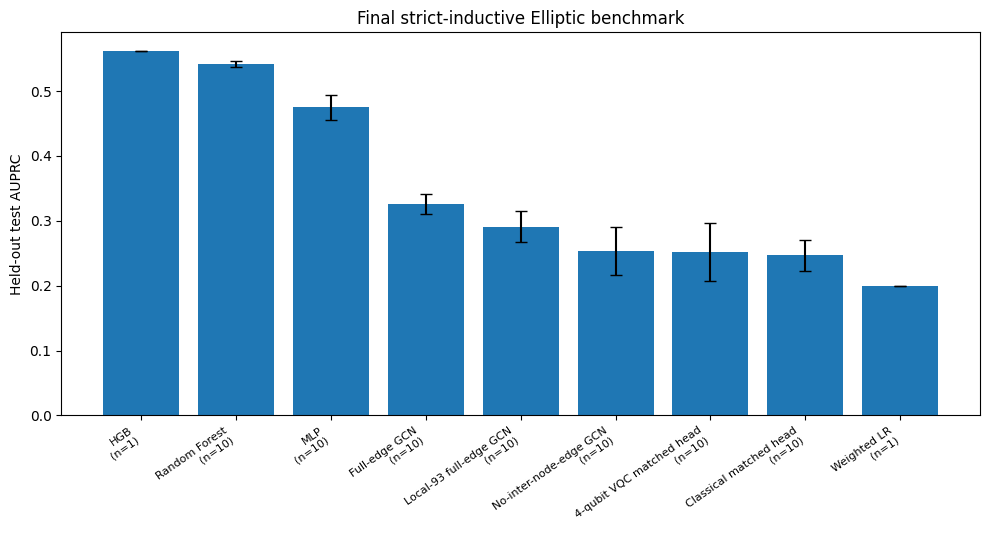

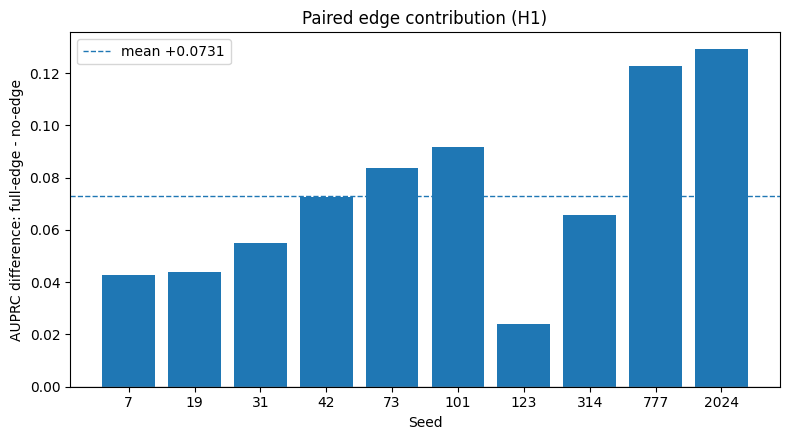

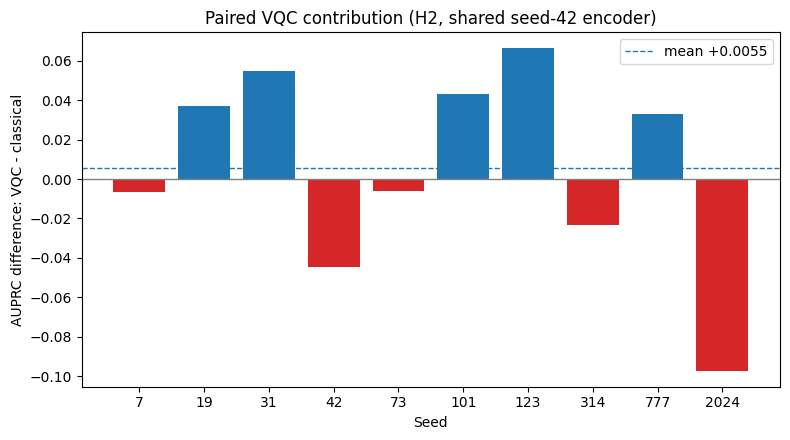

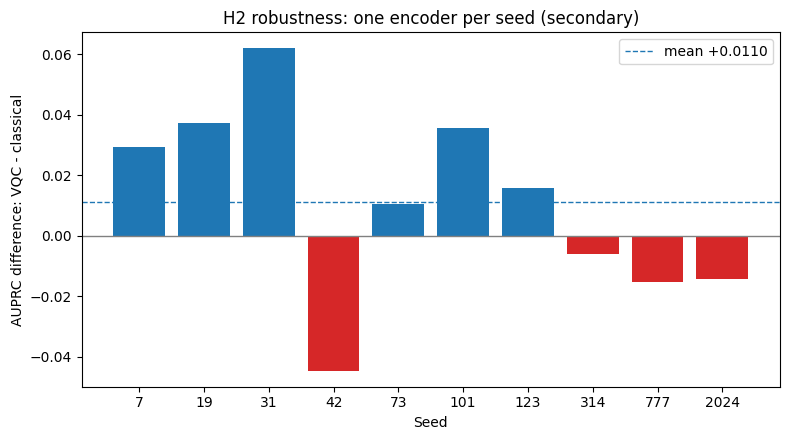

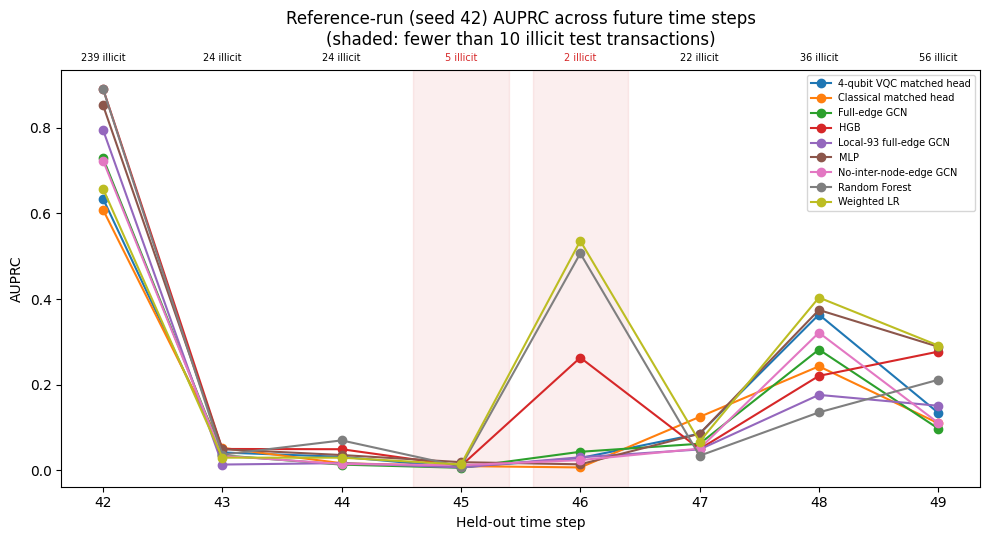

Saved plots to: /kaggle/working/elliptic_final_run/outputs


In [5]:
# ========================== PUBLICATION / QA PLOTS ==========================
import matplotlib.pyplot as plt

# 1) Primary AUPRC bar chart (error bars = SD across seeds; single-run models have none)
sumdf = pd.read_csv(OUT/'summary_metrics.csv').sort_values('auprc_mean', ascending=False)
plt.figure(figsize=(10, 5.5)); x = np.arange(len(sumdf))
plt.bar(x, sumdf['auprc_mean'].to_numpy(), yerr=sumdf['auprc_sd'].fillna(0).to_numpy(), capsize=4)
plt.xticks(x, [f"{m}\n(n={n})" for m, n in zip(sumdf['model'], sumdf['n_runs'])], rotation=35, ha='right', fontsize=8)
plt.ylabel('Held-out test AUPRC'); plt.title('Final strict-inductive Elliptic benchmark')
plt.tight_layout(); plt.savefig(OUT/'primary_auprc.png', dpi=300, bbox_inches='tight'); plt.show()

runs = pd.read_csv(OUT/'all_run_metrics.csv')
def paired_plot(a, b, ylabel, title, fname, table=runs):
    A = table[table.model == a].sort_values('seed'); B = table[table.model == b].sort_values('seed')
    d = A.auprc.to_numpy() - B.auprc.to_numpy(); pos = np.arange(len(d))
    plt.figure(figsize=(8, 4.5)); plt.axhline(0, color='grey', linewidth=1)
    plt.bar(pos, d, color=['tab:blue' if v > 0 else 'tab:red' for v in d])
    plt.axhline(d.mean(), linestyle='--', linewidth=1, label=f'mean {d.mean():+.4f}')
    plt.xticks(pos, A.seed.astype(int)); plt.xlabel('Seed'); plt.ylabel(ylabel); plt.title(title); plt.legend()
    plt.tight_layout(); plt.savefig(OUT/fname, dpi=300, bbox_inches='tight'); plt.show()

# 2) Per-seed edge paired differences (Fig. 8)
paired_plot('Full-edge GCN', 'No-inter-node-edge GCN', 'AUPRC difference: full-edge - no-edge', 'Paired edge contribution (H1)', 'edge_paired_differences.png')
# 3) Per-seed VQC - classical differences (Fig. 9)
paired_plot('4-qubit VQC matched head', 'Classical matched head', 'AUPRC difference: VQC - classical', 'Paired VQC contribution (H2, shared seed-42 encoder)', 'vqc_paired_differences.png')
# 3b) Encoder-robustness version of H2
if (OUT/'encoder_robustness_runs.csv').exists():
    rob = pd.read_csv(OUT/'encoder_robustness_runs.csv')
    paired_plot('4-qubit VQC matched head', 'Classical matched head', 'AUPRC difference: VQC - classical',
                'H2 robustness: one encoder per seed (secondary)', 'vqc_paired_differences_encoder_robustness.png', table=rob)

# 4) Reference per-time-step AUPRC (Fig. 10), with illicit support annotated
step_df = pd.read_csv(OUT/'test_time_step_metrics_reference_seed42.csv')
fig, ax = plt.subplots(figsize=(10, 5.5))
for model, g in step_df.groupby('model'):
    g = g.sort_values('time_step'); ax.plot(g.time_step, g.auprc, marker='o', label=model)
support = step_df.drop_duplicates('time_step').sort_values('time_step')
for _, r in support.iterrows():
    ax.annotate(f"{int(r.illicit)} illicit", (r.time_step, 1.02), ha='center', fontsize=7,
                color='tab:red' if r.illicit < 10 else 'black', xycoords=('data', 'axes fraction'))
    if r.illicit < 10: ax.axvspan(r.time_step - 0.4, r.time_step + 0.4, color='tab:red', alpha=0.08)
ax.set_xlabel('Held-out time step'); ax.set_ylabel('AUPRC')
ax.set_title('Reference-run (seed 42) AUPRC across future time steps\n(shaded: fewer than 10 illicit test transactions)', pad=18)
ax.legend(fontsize=7); plt.tight_layout(); plt.savefig(OUT/'per_time_step_auprc.png', dpi=300, bbox_inches='tight'); plt.show()

print('Saved plots to:', OUT)


## 3. Inspect the final summary

In [6]:
from pathlib import Path
import pandas as pd, json
from IPython.display import display, Markdown

OUT = Path.cwd() / 'elliptic_final_run' / 'outputs'
display(pd.read_csv(OUT/'summary_metrics.csv'))
paired = json.load(open(OUT/'paired_primary_statistics.json'))
for k in ('edge', 'vqc'):
    s = paired[k]
    print(f"{s['comparison']}: diff {s['mean_difference']:+.6f}, CI {s['bootstrap_95_ci']}, gz {s['hedges_gz']:.3f}, "
          f"exact p {s['exact_two_sided_signflip_p']:.6f}, Holm p {s['holm_adjusted_p_across_2_primary_tests']:.6f}, "
          f"favouring A {s['n_pairs_favouring_a']}/10")
if (OUT/'seed42_spot_check.csv').exists(): display(pd.read_csv(OUT/'seed42_spot_check.csv'))
display(Markdown((OUT/'manuscript_values.md').read_text()))

,model,n_runs,auprc_mean,auprc_sd,roc_auc_mean,roc_auc_sd,f1_mean,f1_sd,precision_mean,precision_sd,recall_mean,recall_sd
0,HGB,1,0.562508,NaN,0.870322,NaN,0.563739,NaN,0.667785,NaN,0.487745,NaN
1,Random Forest,10,0.541948,0.003991,0.841444,0.012982,0.588064,0.006585,0.782323,0.026808,0.471324,0.002842
2,MLP,10,0.474945,0.018842,0.874819,0.005677,0.525477,0.048505,0.640414,0.134616,0.458824,0.022782
3,Full-edge GCN,10,0.326027,0.015864,0.796374,0.007943,0.188403,0.008376,0.112811,0.006398,0.574265,0.025629
4,Local-93 full-edge GCN,10,0.291104,0.023966,0.754800,0.015963,0.157360,0.010183,0.090341,0.007048,0.616422,0.036432
5,No-inter-node-edge GCN,10,0.252901,0.036901,0.809596,0.004526,0.184063,0.024292,0.107327,0.016331,0.682598,0.102442
6,4-qubit VQC matched head,10,0.252151,0.044465,0.772135,0.019042,0.147673,0.025766,0.082678,0.018257,0.772059,0.125981
7,Classical matched head,10,0.246610,0.023551,0.766264,0.009532,0.122256,0.062358,0.091262,0.060682,0.593382,0.329068
8,Weighted LR,1,0.199676,NaN,0.855632,NaN,0.214682,NaN,0.123824,NaN,0.806373,NaN


H1: edge contribution: diff +0.073126, CI [0.0536625294975146, 0.09406717549621305], gz 1.946, exact p 0.001953, Holm p 0.003906, favouring A 10/10
H2: VQC contribution: diff +0.005541, CI [-0.026277067380915148, 0.03365711068777395], gz 0.099, exact p 0.738281, Holm p 0.738281, favouring A 5/10


,model,stored_auprc,rerun_auprc,abs_diff,exact_match
0,Full-edge GCN,0.349912,0.349912,0.0,True
1,No-inter-node-edge GCN,0.277271,0.277271,0.0,True
2,Local-93 full-edge GCN,0.275481,0.275481,0.0,True
3,Classical matched head,0.243397,0.243397,0.0,True
4,4-qubit VQC matched head,0.198809,0.198809,0.0,True


# Manuscript values generated by this execution

## Table 2. Split counts

| Split | Time steps | Labeled nodes | Within-period directed edges | Licit | Illicit |
|---|---|---|---|---|---|
| train | 1-34 | 29,894 | 22,898 | 26,432 | 3,462 |
| val | 35-41 | 7,829 | 6,509 | 7,154 | 675 |
| test | 42-49 | 8,841 | 7,217 | 8,433 | 408 |

## Table 3. Held-out test metrics

| Model | Runs | AUPRC | SD | ROC-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|---|---|
| HGB | 1 | 0.562508 | - | 0.870322 | 0.563739 | 0.667785 | 0.487745 |
| Random Forest | 10 | 0.541948 | 0.003991 | 0.841444 | 0.588064 | 0.782323 | 0.471324 |
| MLP | 10 | 0.474945 | 0.018842 | 0.874819 | 0.525477 | 0.640414 | 0.458824 |
| Full-edge GCN | 10 | 0.326027 | 0.015864 | 0.796374 | 0.188403 | 0.112811 | 0.574265 |
| Local-93 full-edge GCN | 10 | 0.291104 | 0.023966 | 0.754800 | 0.157360 | 0.090341 | 0.616422 |
| No-inter-node-edge GCN | 10 | 0.252901 | 0.036901 | 0.809596 | 0.184063 | 0.107327 | 0.682598 |
| 4-qubit VQC matched head | 10 | 0.252151 | 0.044465 | 0.772135 | 0.147673 | 0.082678 | 0.772059 |
| Classical matched head | 10 | 0.246610 | 0.023551 | 0.766264 | 0.122256 | 0.091262 | 0.593382 |
| Weighted LR | 1 | 0.199676 | - | 0.855632 | 0.214682 | 0.123824 | 0.806373 |

## Table 4. H1 edge contribution

| Quantity | Value |
|---|---|
| Full-edge GCN | 0.326027 +/- 0.015864 |
| No-inter-node-edge GCN | 0.252901 +/- 0.036901 |
| Mean difference | +0.073126 |
| 95% bootstrap CI | [0.053663, 0.094067] |
| Hedges gz | 1.946 |
| Exact sign-flip p | 0.001953 |
| Holm-adjusted p | 0.003906 |
| Seeds favouring A | 10/10 |

## Table 5. H2 VQC contribution

| Quantity | Value |
|---|---|
| 4-qubit VQC matched head | 0.252151 +/- 0.044465 |
| Classical matched head | 0.246610 +/- 0.023551 |
| Mean difference | +0.005541 |
| 95% bootstrap CI | [-0.026277, 0.033657] |
| Hedges gz | 0.099 |
| Exact sign-flip p | 0.738281 |
| Holm-adjusted p | 0.738281 |
| Seeds favouring A | 5/10 |

## Section 5.5. Local-93 sensitivity (secondary)

Local-93 minus full-165 GCN = -0.034923; 95% bootstrap CI [-0.049480, -0.019475]; exact p = 0.005859; Hedges gz = -1.247.

## H2 encoder robustness (secondary, one encoder per seed)

Classical 0.357785 +/- 0.079332; VQC 0.368800 +/- 0.083047; difference +0.011015; 95% CI [-0.007449, 0.029656]; exact p = 0.294922; Hedges gz = 0.319; seeds favouring VQC 6/10.

## Other values

- Shared encoder (seed 42) best validation AUPRC 0.463211 at epoch 2.
- HGB boosting iterations realised: 200; LR lbfgs iterations: 234.
- Dataset: 203,769 transactions, 165 model features, 234,355 source edges, time steps 1-49.
- Seed-42 spot check: all five reference records reproduced exactly.

## Reproducibility and interpretation notes

- The primary VQC-versus-classical result is conditional on the shared encoder trained with seed 42. The one-encoder-per-seed result is secondary robustness analysis.
- The exact paired sign-flip test with Holm adjustment is the prespecified inferential test. The percentile bootstrap interval is descriptive and can disagree with the exact test at ten pairs.
- These values were regenerated from this execution and these input files. Reconcile the manuscript tables and claims to these outputs before submission.

## Input dataset SHA-256

| File | SHA-256 |
|---|---|
| `elliptic_txs_features.csv` | `fd7f83573443c9e302e371d3f110e3b6224160f5d1ed8a287757936127800ff0` |
| `elliptic_txs_classes.csv` | `93e2e7b2405c735ba752bf6ba06b947561deddd1f5a8fc91e46f6a4c0e439493` |
| `elliptic_txs_edgelist.csv` | `a35053ba68a98e4382cae2ba65b9d9e36b23b6439e02dff084971b1b72a5156e` |


## 4. Files produced by the notebook
- `manuscript_values.md` - every number for the abstract, Tables 2-5 and Sections 5.2-5.6
- `summary_metrics.csv`, `all_run_metrics.csv`, `per_run_metrics.csv`, `per_model_metrics/*.csv`
- `paired_primary_statistics.json` (H1, H2, Holm), `feature_sensitivity_statistics.json` (local-93)
- `encoder_robustness_runs.csv`, `encoder_robustness_statistics.json` (secondary H2 robustness)
- `seed42_spot_check.csv`
- `test_time_step_metrics_reference_seed42.csv`
- `predictions/*.npy` (every run, plus `y_test.npy`, `txid_test.npy`, `timestep_test.npy`)
- `quantum_balanced_256_node_subsets.csv`, `shared_encoder_embeddings.npz`, `scaler_stats.npz`
- `dataset_manifest.json` (counts + SHA-256), `experiment_config.json`, `environment_versions.json`, `run_log.txt`
- `checkpoints/`, publication/QA plots

### Interpretation rule
Use only the numbers produced by this notebook (see `manuscript_values.md`). Do not mix them with values from
earlier executions.